# LC25000 Colon Dedup Pipeline — Consolidated & Idempotent

Recovers the ~500 original colon images (250 benign + 250 adenocarcinoma)
from the 10,000 rotation-augmented LC25000 colon images.

- idempotent stages with done marker to drive.

### Drive layout

```
MyDrive/LC25000_colon/
  raw/colon_raw_all.zip          <- original 10,000 images (backup)
  representatives/
    colon_n/    *.jpeg           <- deduped originals
    colon_aca/  *.jpeg
  logs/
    colon_n_clusters.csv
    colon_aca_clusters.csv
    colon_n_splits.csv
    colon_aca_splits.csv
    colon_n_merges.csv
    colon_aca_merges.csv
    final_manifest.csv           <- authoritative final image list
  markers/  *.done               <- stage completion markers
```


1. Setup & Drive structure

In [ ]:
!pip install -q datasets opencv-python-headless scikit-learn tqdm pillow pandas

In [ ]:
import os
import csv
import shutil
import statistics

import cv2
import numpy as np
import pandas as pd
from tqdm import tqdm
from sklearn.cluster import KMeans
from google.colab import drive

drive.mount("/content/drive")

# Path
DRIVE_ROOT  = "/content/drive/MyDrive/LC25000_colon"
RAW_BACKUP  = f"{DRIVE_ROOT}/raw"
REP_DIR     = f"{DRIVE_ROOT}/representatives"
LOG_DIR     = f"{DRIVE_ROOT}/logs"
MARKER_DIR  = f"{DRIVE_ROOT}/markers"

RAW_DIR     = "/content/raw"          # (wiped on disconnect)
RAW_ZIP     = f"{RAW_BACKUP}/colon_raw_all.zip"

CLASSES     = ["colon_n", "colon_aca"]
N_CLUSTERS  = 250
EXPECTED_SZ = 5000 / N_CLUSTERS

for d in [RAW_BACKUP, REP_DIR, LOG_DIR, MARKER_DIR] + [f"{REP_DIR}/{c}" for c in CLASSES]:
    os.makedirs(d, exist_ok=True)
for c in CLASSES:
    os.makedirs(f"{RAW_DIR}/{c}", exist_ok=True)


# Markers
def marker_path(name):
    return os.path.join(MARKER_DIR, f"{name}.done")

def is_done(name):
    return os.path.exists(marker_path(name))

def mark_done(name, note=""):
    with open(marker_path(name), "w") as f:
        f.write(note or "done")

def reset_stage(name):
    """Delete a stage marker so the stage reruns next time."""
    p = marker_path(name)
    if os.path.exists(p):
        os.remove(p)
        print(f"Reset: {name} will rerun")
    else:
        print(f"No marker for {name}")

print("\nDrive structure ready at", DRIVE_ROOT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Drive structure ready at /content/drive/MyDrive/LC25000_colon


2. Get raw images

Three cases:
- already on local scratch: do nothing
- Drive backup exists: unzip from Drive
- neither: download from Hugging Face once, then back up to Drive permanently.

In [ ]:
def raw_present():
    return all(len(os.listdir(f"{RAW_DIR}/{c}")) > 0 for c in CLASSES)


if raw_present():
    print("Raw images already on local scratch.")

elif os.path.exists(RAW_ZIP):
    print("Restoring raw images from Drive backup...")
    shutil.unpack_archive(RAW_ZIP, RAW_DIR)
    print("Restored:", {c: len(os.listdir(f"{RAW_DIR}/{c}")) for c in CLASSES})

else:
    print("First run (fresh download)")
    from datasets import load_dataset

    ds = load_dataset("1aurent/LC25000", split="train")
    organ_names = ds.features["organ"].names
    label_names = ds.features["label"].names
    colon_idx  = organ_names.index("colon")
    benign_idx = label_names.index("benign")
    aca_idx    = label_names.index("adenocarcinomas")

    n_saved = {c: 0 for c in CLASSES}
    for ex in tqdm(ds):
        if ex["organ"] != colon_idx:
            continue
        if ex["label"] == benign_idx:
            key = "colon_n"
        elif ex["label"] == aca_idx:
            key = "colon_aca"
        else:
            continue
        ex["image"].save(os.path.join(f"{RAW_DIR}/{key}", f"{key}_{n_saved[key]:05d}.jpeg"))
        n_saved[key] += 1
    print("Downloaded:", n_saved)

    shutil.make_archive("/content/colon_raw_all", "zip", RAW_DIR)
    shutil.move("/content/colon_raw_all.zip", RAW_ZIP)
    print("Backed up to", RAW_ZIP)

mark_done("stage2_raw", str({c: len(os.listdir(f"{RAW_DIR}/{c}")) for c in CLASSES}))


Raw images already on local scratch.


3. Feature extraction and over-clustering

- Lab histogram
- Sharpness based on Laplacian variance.
- ORB descriptors (cached per image path)

In [ ]:
def compute_lab_histogram(image_path, bins=32):
    """96-number colour fingerprint: 32 bins x 3 Lab channels, L2-normalised per channel."""
    img = cv2.imread(image_path)
    if img is None:
        return None
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2Lab)
    parts = []
    for ch in range(3):
        h = cv2.calcHist([lab], [ch], None, [bins], [0, 256])
        parts.append(cv2.normalize(h, h).flatten())
    return np.concatenate(parts)


def sharpness_score(image_path):
    """Laplacian variance  (higher means sharper/more in focus)."""
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        return 0.0
    return float(cv2.Laplacian(img, cv2.CV_64F).var())


_ORB = cv2.ORB_create(nfeatures=500)
_DESC_CACHE = {}

def orb_descriptors(path):
    """Cached ORB descriptors."""
    if path not in _DESC_CACHE:
        img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
        if img is None:
            _DESC_CACHE[path] = None
        else:
            _, des = _ORB.detectAndCompute(img, None)
            _DESC_CACHE[path] = des
    return _DESC_CACHE[path]


_BF = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)

def orb_match_score(path_a, path_b, distance_thresh=40):
    """Count of strong mutual ORB keypoint matches. High means same original, just rotated."""
    des_a, des_b = orb_descriptors(path_a), orb_descriptors(path_b)
    if des_a is None or des_b is None:
        return 0
    return sum(1 for m in _BF.match(des_a, des_b) if m.distance < distance_thresh)


def load_features(input_dir):
    """Lab histograms for every image in a class folder.
    sorted() keeps file order stable across colab sessions so cluster IDs stay meaningful."""
    files = sorted(f for f in os.listdir(input_dir) if f.lower().endswith(".jpeg"))
    paths = [os.path.join(input_dir, f) for f in files]
    feats, valid = [], []
    for p in tqdm(paths, desc="histograms"):
        f = compute_lab_histogram(p)
        if f is not None:
            feats.append(f)
            valid.append(p)
    return np.array(feats), valid


def cluster_class(cls):
    """ k-means"""
    feats, paths = load_features(f"{RAW_DIR}/{cls}")
    km = KMeans(n_clusters=N_CLUSTERS, random_state=42, n_init=10)
    labels = km.fit_predict(feats)
    return labels, paths


In [ ]:
# cluster each class and save sharpest representative per cluster

CLUSTER_STATE = {}   # cls -> (labels, paths), needed by stages 4 and 5

for cls in CLASSES:
    log_csv = f"{LOG_DIR}/{cls}_clusters.csv"

    if is_done(f"stage3_{cls}") and os.path.exists(log_csv):
        print(f"[{cls}] Stage 3 already done. Reusing clusters from {log_csv}")
        labels, paths = cluster_class(cls)
        CLUSTER_STATE[cls] = (labels, paths)
        continue

    print(f"\n[{cls}] Stage 3: clustering into {N_CLUSTERS} groups.")
    labels, paths = cluster_class(cls)
    CLUSTER_STATE[cls] = (labels, paths)

    rows = []
    for cid in tqdm(range(N_CLUSTERS), desc="representatives"):
        idx = np.where(labels == cid)[0]
        if len(idx) == 0:
            continue
        members = [paths[i] for i in idx]
        rep = members[int(np.argmax([sharpness_score(p) for p in members]))]
        out_name = f"cluster{cid:04d}_{os.path.basename(rep)}"
        shutil.copy(rep, os.path.join(f"{REP_DIR}/{cls}", out_name))
        rows.append({"cluster_id": cid, "n_members": len(members),
                     "representative": rep, "saved_as": out_name})

    pd.DataFrame(rows).to_csv(log_csv, index=False)
    mark_done(f"stage3_{cls}", f"{len(rows)} clusters")
    print(f"[{cls}] {len(rows)} representatives saved")

for cls in CLASSES:
    df = pd.read_csv(f"{LOG_DIR}/{cls}_clusters.csv")
    print(f"{cls}: {len(df)} clusters | avg {df.n_members.mean():.1f} "
          f"| min {df.n_members.min()} | max {df.n_members.max()}")


[colon_n] Stage 3 already done. Reusing clusters from /content/drive/MyDrive/LC25000_colon/logs/colon_n_clusters.csv


histograms: 100%|██████████| 5000/5000 [00:52<00:00, 95.67it/s]


[colon_aca] Stage 3 already done. Reusing clusters from /content/drive/MyDrive/LC25000_colon/logs/colon_aca_clusters.csv


histograms: 100%|██████████| 5000/5000 [00:53<00:00, 93.43it/s]


colon_n: 250 clusters | avg 20.0 | min 4 | max 67
colon_aca: 250 clusters | avg 20.0 | min 2 | max 80


4. Split oversized clusters

A cluster far above the expected ~20 members usually means several different
originals got merged. Re-clustering within just that group separates them.

Small clusters are left alone

In [ ]:
SPLIT_THRESHOLD = 1.5
for cls in CLASSES:
    split_csv = f"{LOG_DIR}/{cls}_splits.csv"

    if is_done(f"stage4_{cls}"):
        n = len(pd.read_csv(split_csv)) if os.path.exists(split_csv) else 0
        print(f"[{cls}] Stage 4 already done. {n} sub-representatives on Drive, skipping")
        continue

    labels, paths = CLUSTER_STATE[cls]
    df = pd.read_csv(f"{LOG_DIR}/{cls}_clusters.csv")

    over = df[df.n_members > EXPECTED_SZ * SPLIT_THRESHOLD].copy()
    over["est_sub"] = (over.n_members / EXPECTED_SZ).round().clip(lower=2).astype(int)
    print(f"\n[{cls}] Stage 4: splitting {len(over)} oversized clusters "
          f"(>{EXPECTED_SZ * SPLIT_THRESHOLD:.0f} members)")

    new_rows = []
    for _, row in tqdm(list(over.iterrows()), desc="splitting"):
        cid, n_sub = int(row.cluster_id), int(row.est_sub)

        # remove the old merged representative because it conflated several originals
        old = os.path.join(f"{REP_DIR}/{cls}", row.saved_as)
        if os.path.exists(old):
            os.remove(old)

        members = [paths[i] for i in np.where(labels == cid)[0]]
        feats, valid = [], []
        for p in members:
            f = compute_lab_histogram(p)
            if f is not None:
                feats.append(f)
                valid.append(p)

        km = KMeans(n_clusters=min(n_sub, len(valid)), random_state=42, n_init=10)
        sub_labels = km.fit_predict(np.array(feats))

        for sid in range(sub_labels.max() + 1):
            sub = [valid[i] for i in np.where(sub_labels == sid)[0]]
            if not sub:
                continue
            rep = sub[int(np.argmax([sharpness_score(p) for p in sub]))]
            out_name = f"cluster{cid:04d}_sub{sid}_{os.path.basename(rep)}"
            shutil.copy(rep, os.path.join(f"{REP_DIR}/{cls}", out_name))
            new_rows.append({"orig_cluster_id": cid, "sub_id": sid,
                             "n_members": len(sub), "representative": rep,
                             "saved_as": out_name})

    pd.DataFrame(new_rows).to_csv(split_csv, index=False)
    mark_done(f"stage4_{cls}", f"{len(over)} split into {len(new_rows)}")
    print(f"[{cls}] {len(over)} merged clusters -> {len(new_rows)} corrected representatives")

for cls in CLASSES:
    n = len([f for f in os.listdir(f"{REP_DIR}/{cls}") if f.lower().endswith(".jpeg")])
    print(f"{cls}: {n} representatives on Drive after splitting")


[colon_n] Stage 4 already done. 54 sub-representatives on Drive, skipping
[colon_aca] Stage 4 already done. 49 sub-representatives on Drive, skipping
colon_n: 243 representatives on Drive after splitting
colon_aca: 246 representatives on Drive after splitting


In [ ]:
# Safe rebuild: restores files missing due to Drive write drops,
# but never restores anything Stage 5 legitimately removed.
for cls in CLASSES:
    stage3 = pd.read_csv(f"{LOG_DIR}/{cls}_clusters.csv")
    stage4 = pd.read_csv(f"{LOG_DIR}/{cls}_splits.csv")
    merge_log = f"{LOG_DIR}/{cls}_merges.csv"
    merges_removed = set(pd.read_csv(merge_log)["removed"]) if os.path.exists(merge_log) else set()

    split_ids = set(stage4["orig_cluster_id"])
    expected = {}
    for _, r in stage3[~stage3["cluster_id"].isin(split_ids)].iterrows():
        expected[r["saved_as"]] = r["representative"]
    for _, r in stage4.iterrows():
        expected[r["saved_as"]] = r["representative"]

    # never restore anything Stage 5 removed
    expected = {k: v for k, v in expected.items() if k not in merges_removed}

    rep_dir = f"{REP_DIR}/{cls}"
    actual = set(f for f in os.listdir(rep_dir) if f.lower().endswith(".jpeg"))
    missing = {k: v for k, v in expected.items() if k not in actual}

    print(f"[{cls}] expected {len(expected)}, on disk {len(actual)}, missing {len(missing)}")
    for saved_as, src in tqdm(list(missing.items()), desc=f"restoring {cls}"):
        if os.path.exists(src):
            shutil.copy(src, os.path.join(rep_dir, saved_as))

    n_now = len([f for f in os.listdir(rep_dir) if f.lower().endswith(".jpeg")])
    print(f"[{cls}] now {n_now}/{len(expected)} on disk")

[colon_n] expected 243, on disk 243, missing 0


restoring colon_n: 0it [00:00, ?it/s]


[colon_n] now 243/243 on disk
[colon_aca] expected 246, on disk 246, missing 0


restoring colon_aca: 0it [00:00, ?it/s]

[colon_aca] now 246/246 on disk


5. ORB consolidation merge

Splitting causes some originals now have two
or more representatives.

Each representative is compared against only its nearest neighbours in
histogram space, and ORB descriptors are cached, so this is
minutes rather than hours. Pairs scoring above the threshold are the same
original. The blurrier one is dropped.

In [ ]:
MERGE_ORB_THRESHOLD = 40
N_NEIGHBOURS        = 10

for cls in CLASSES:
    merge_csv = f"{LOG_DIR}/{cls}_merges.csv"

    if is_done(f"stage5_{cls}"):
        n = len(pd.read_csv(merge_csv)) if os.path.exists(merge_csv) else 0
        print(f"[{cls}] Stage 5 already done — {n} duplicates removed, skipping")
        continue

    rep_dir = f"{REP_DIR}/{cls}"
    rep_files = sorted(f for f in os.listdir(rep_dir) if f.lower().endswith(".jpeg"))
    rep_paths = [os.path.join(rep_dir, f) for f in rep_files]
    print(f"\n[{cls}] Stage 5: consolidating {len(rep_paths)} representatives...")

    feats = []
    for p in tqdm(rep_paths, desc="histograms"):
        feats.append(compute_lab_histogram(p))
    feats = np.array(feats)

    # candidate pairs = mutual nearest neighbours in histogram space
    dists = np.linalg.norm(feats[:, None, :] - feats[None, :, :], axis=2)
    np.fill_diagonal(dists, np.inf)
    k = min(N_NEIGHBOURS, len(rep_paths) - 1)
    pairs = {(min(i, j), max(i, j))
             for i in range(len(rep_paths))
             for j in np.argsort(dists[i])[:k]}

    merged, removed = [], set()
    for i, j in tqdm(sorted(pairs), desc="ORB checks"):
        if i in removed or j in removed:
            continue
        score = orb_match_score(rep_paths[i], rep_paths[j])
        if score >= MERGE_ORB_THRESHOLD:
            # same original: keep the sharper image, drop the other
            si, sj = sharpness_score(rep_paths[i]), sharpness_score(rep_paths[j])
            drop, keep = (j, i) if si >= sj else (i, j)
            removed.add(drop)
            merged.append({"kept": os.path.basename(rep_paths[keep]),
                           "removed": os.path.basename(rep_paths[drop]),
                           "orb_score": score})

    for idx in removed:
        os.remove(rep_paths[idx])

    pd.DataFrame(merged).to_csv(merge_csv, index=False)
    mark_done(f"stage5_{cls}", f"{len(removed)} removed")
    print(f"[{cls}] removed {len(removed)} duplicates -> {len(rep_paths) - len(removed)} remain")


[colon_n] Stage 5 already done — 36 duplicates removed, skipping
[colon_aca] Stage 5 already done — 30 duplicates removed, skipping


6. Verify & spot-check

Exactly 250 is unlikely and not
required. Then a visual check on a few merge decisions. They should look like rotations of
one tile.

In [ ]:
print("Final counts vs. ground truth (250 originals per class):\n")
total = 0
for cls in CLASSES:
    n = len([f for f in os.listdir(f"{REP_DIR}/{cls}") if f.lower().endswith(".jpeg")])
    total += n
    delta = n - N_CLUSTERS
    print(f"  {cls:10s} {n:4d}   ({delta:+d} vs 250, {abs(delta)/N_CLUSTERS*100:.1f}% off)")
print(f"\n  {'TOTAL':10s} {total:4d}   (ground truth 500)")

for cls in CLASSES:
    p = f"{LOG_DIR}/{cls}_merges.csv"
    if os.path.exists(p):
        df = pd.read_csv(p)
        if len(df):
            print(f"\n{cls}: {len(df)} merges | ORB score range "
                  f"{df.orb_score.min()}-{df.orb_score.max()}, median {df.orb_score.median():.0f}")


Final counts vs. ground truth (250 originals per class):

  colon_n     243   (-7 vs 250, 2.8% off)
  colon_aca   246   (-4 vs 250, 1.6% off)

  TOTAL       489   (ground truth 500)

colon_n: 36 merges | ORB score range 40-303, median 48

colon_aca: 30 merges | ORB score range 41-332, median 140


Showing the 3 LOWEST-scoring merges for colon_aca (most likely to be wrong).
Each pair should look like two views of the same tissue, rotated.



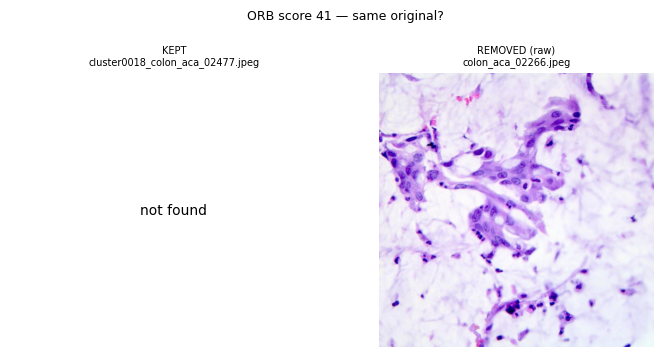

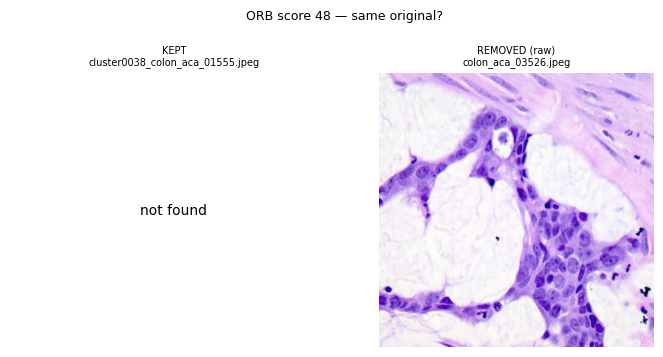

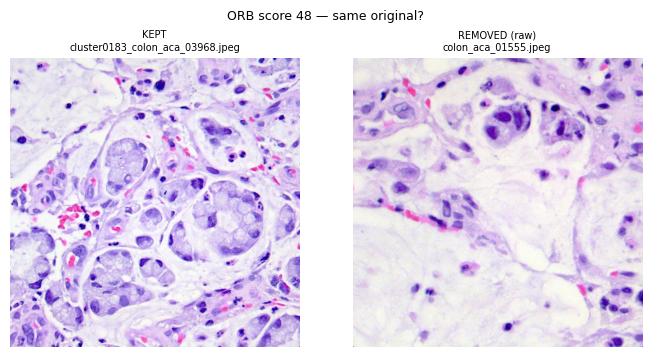

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

SPOT_CHECK_CLASS = "colon_aca"
N_PAIRS = 3

merge_csv = f"{LOG_DIR}/{SPOT_CHECK_CLASS}_merges.csv"
if not os.path.exists(merge_csv) or len(pd.read_csv(merge_csv)) == 0:
    print(f"No merges recorded for {SPOT_CHECK_CLASS}.")
else:
    stage3 = pd.read_csv(f"{LOG_DIR}/{SPOT_CHECK_CLASS}_clusters.csv")
    stage4 = pd.read_csv(f"{LOG_DIR}/{SPOT_CHECK_CLASS}_splits.csv")
    saved_to_src = dict(zip(stage3["saved_as"], stage3["representative"]))
    saved_to_src.update(dict(zip(stage4["saved_as"], stage4["representative"])))

    df = pd.read_csv(merge_csv).sort_values("orb_score").head(N_PAIRS)
    print(f"Showing the {N_PAIRS} LOWEST-scoring merges for {SPOT_CHECK_CLASS} (most likely to be wrong).")
    print("Each pair should look like two views of the same tissue, rotated.\n")

    for _, r in df.iterrows():
        kept_path = os.path.join(f"{REP_DIR}/{SPOT_CHECK_CLASS}", r.kept)
        removed_path = saved_to_src.get(r.removed)   # raw source of the deleted representative

        fig, axes = plt.subplots(1, 2, figsize=(7, 3.6))
        for ax, path, title in [(axes[0], kept_path, f"KEPT\n{r.kept[:40]}"),
                                (axes[1], removed_path, f"REMOVED (raw)\n{os.path.basename(removed_path) if removed_path else '?'}")]:
            if path and os.path.exists(path):
                ax.imshow(Image.open(path))
            else:
                ax.text(0.5, 0.5, "not found", ha="center", va="center")
            ax.set_title(title, fontsize=7)
            ax.axis("off")
        fig.suptitle(f"ORB score {r.orb_score} — same original?", fontsize=9)
        plt.tight_layout()
        plt.show()

7. Manifest

One authoritative CSV listing every surviving representative, built by reading
what is actually on Drive.

This is the folders to copy into QuPath's `images/` folder.

In [ ]:
rows = []
for cls in CLASSES:
    d = f"{REP_DIR}/{cls}"
    for f in sorted(x for x in os.listdir(d) if x.lower().endswith(".jpeg")):
        rows.append({
            "class": cls,
            "filename": f,
            "drive_path": f"{d}/{f}",
            "from_split": "_sub" in f,
        })

manifest = pd.DataFrame(rows)
manifest_path = f"{LOG_DIR}/final_manifest.csv"
manifest.to_csv(manifest_path, index=False)
mark_done("stage7_manifest", f"{len(manifest)} images")

print(f"Manifest: {manifest_path}\n")
print(manifest.groupby("class").agg(
    images=("filename", "count"),
    from_split=("from_split", "sum"),
))
print(f"\nTotal: {len(manifest)} representative images")
print(f"\nReady for QuPath. Copy these folders into your project's images/ folder:")
for cls in CLASSES:
    print(f"  {REP_DIR}/{cls}")


Manifest: /content/drive/MyDrive/LC25000_colon/logs/final_manifest.csv

           images  from_split
class                        
colon_aca     246          43
colon_n       243          47

Total: 489 representative images

Ready for QuPath. Copy these folders into your project's images/ folder:
  /content/drive/MyDrive/LC25000_colon/representatives/colon_n
  /content/drive/MyDrive/LC25000_colon/representatives/colon_aca


---
## Rerunning a stage

Stages skip themselves once complete. To force one to rerun, delete its
marker and re-execute its cell:

```python
reset_stage("stage5_colon_aca")     # then rerun the Stage 5 cell
```

Markers: `stage2_raw`, `stage3_<class>`, `stage4_<class>`, `stage5_<class>`,
`stage7_manifest`.

Note that stages build on each other — resetting Stage 4 after Stage 5 has run
will not restore the duplicates Stage 5 deleted. To redo the pipeline from
Stage 3 onward, clear the representative folders and all markers from Stage 3 on:

```python
for c in CLASSES:
    shutil.rmtree(f"{REP_DIR}/{c}"); os.makedirs(f"{REP_DIR}/{c}")
    for s in ["stage3", "stage4", "stage5"]:
        reset_stage(f"{s}_{c}")
```

The raw images and their Drive backup are never touched by a reset.

check variance inter-cluster